In [ ]:
from google.colab import files
uploaded = files.upload()

Saving retail_store_inventory.csv to retail_store_inventory.csv


In [ ]:
import pandas as pd
df = pd.read_csv('retail_store_inventory.csv')
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from IPython.display import display

# Use the df already loaded in your notebook.
# Upload a CSV only if df does not exist.
if "df" not in globals():
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(filename)

# Preserve the original dataset for reporting
raw_df = df.copy()
original_shape = raw_df.shape

# Normalize column names: "Store ID" -> "store_id"
df.columns = [
    re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")
    for c in df.columns
]

original_missing_counts = df.isna().sum()

required_columns = [
    "date", "store_id", "product_id", "category", "region",
    "inventory_level", "units_sold", "units_ordered",
    "demand_forecast", "price", "discount",
    "weather_condition", "holiday_promotion",
    "competitor_pricing", "seasonality"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These expected columns are missing: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("DATASET DETAILS")
print("Dataset file: retail_store_inventory.csv")
print("Original records:", original_shape[0])
print("Original attributes:", original_shape[1])
print("Original dataset shape:", original_shape)

print("\nCOLUMN NAMES AND DATA TYPES")
display(df.dtypes.rename("Data Type").to_frame())

print("\nMISSING VALUES IN ORIGINAL DATA")
display(
    original_missing_counts[original_missing_counts > 0]
    .rename("Missing Count")
    .to_frame()
)

print("\nFIRST FIVE RECORDS")
display(df.head())

DATASET DETAILS
Dataset file: retail_store_inventory.csv
Original records: 73100
Original attributes: 15
Original dataset shape: (73100, 15)

COLUMN NAMES AND DATA TYPES


,Data Type
date,object
store_id,object
product_id,object
category,object
region,object
inventory_level,int64
units_sold,int64
units_ordered,int64
demand_forecast,float64
price,float64



MISSING VALUES IN ORIGINAL DATA


,Missing Count



FIRST FIVE RECORDS


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,weather_condition,holiday_promotion,competitor_pricing,seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
# 1. Convert the columns to their appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_columns = [
    "inventory_level", "units_sold", "units_ordered",
    "demand_forecast", "price", "discount",
    "holiday_promotion", "competitor_pricing"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. Identify invalid values
invalid_counts = {}

# Negative inventory, demand and sales quantities are invalid
for col in [
    "inventory_level", "units_sold",
    "units_ordered", "demand_forecast"
]:
    invalid_counts[col] = int((df[col] < 0).sum())
    df.loc[df[col] < 0, col] = np.nan

# Prices must be positive
for col in ["price", "competitor_pricing"]:
    invalid_counts[col] = int((df[col] <= 0).sum())
    df.loc[df[col] <= 0, col] = np.nan

# Treat discounts outside 0–100% as invalid
bad_discount = (
    df["discount"].notna()
    & ~df["discount"].between(0, 100)
)
invalid_counts["discount"] = int(bad_discount.sum())
df.loc[bad_discount, "discount"] = np.nan

# 3. Standardize categorical data
id_columns = ["store_id", "product_id"]

categorical_columns = [
    "store_id", "product_id", "category",
    "region", "weather_condition", "seasonality"
]

for col in categorical_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .replace("", pd.NA)
    )

    if col in id_columns:
        df[col] = df[col].str.upper()
    else:
        df[col] = df[col].str.title()

# 4. Remove rows with invalid dates and exact duplicate records
invalid_date_rows = int(df["date"].isna().sum())
df = df.dropna(subset=["date"])

duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates()

# 5. Missing target values cannot be used for supervised ML
missing_target_rows = int(df["units_sold"].isna().sum())
df = df.dropna(subset=["units_sold"])

# 6. Handle missing categorical values
for col in categorical_columns:
    if col in id_columns:
        df[col] = df[col].fillna("UNKNOWN").astype(str)
    else:
        mode_values = df[col].mode(dropna=True)
        replacement = (
            mode_values.iloc[0] if not mode_values.empty else "Unknown"
        )
        df[col] = df[col].fillna(replacement).astype(str)

# 7. Impute missing numerical inputs using the median
for col in numeric_columns:
    if col == "units_sold":
        continue

    median_value = df[col].median()

    if pd.notna(median_value):
        df[col] = df[col].fillna(median_value)
    else:
        df[col] = df[col].fillna(0)

# 8. Detect and cap outliers using the IQR method.
# Preserve units_sold values because it is the prediction target.
outlier_columns = [
    "inventory_level", "units_ordered",
    "demand_forecast", "price", "competitor_pricing"
]

outlier_counts = {}

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    if pd.notna(iqr) and iqr > 0:
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_mask = (
            (df[col] < lower_bound) | (df[col] > upper_bound)
        )
        outlier_counts[col] = int(outlier_mask.sum())

        df[col] = df[col].clip(lower_bound, upper_bound)
    else:
        outlier_counts[col] = 0

df = df.reset_index(drop=True)

# 9. Display the cleaning report
print("DATA PREPROCESSING REPORT")
print("Rows with invalid dates removed:", invalid_date_rows)
print("Exact duplicate rows removed:", duplicates_removed)
print("Rows with missing/invalid sales targets removed:", missing_target_rows)

print("\nInvalid values identified:")
display(pd.Series(invalid_counts, name="Invalid Values"))

print("\nOutliers capped using IQR:")
display(pd.Series(outlier_counts, name="Outliers Capped"))

print("\nOriginal shape:", original_shape)
print("Cleaned shape:", df.shape)
print("Remaining missing cells:", int(df.isna().sum().sum()))

print("\nCleaned dataset preview:")
display(df.head())

DATA PREPROCESSING REPORT
Rows with invalid dates removed: 0
Exact duplicate rows removed: 0
Rows with missing/invalid sales targets removed: 0

Invalid values identified:


,Invalid Values
inventory_level,0
units_sold,0
units_ordered,0
demand_forecast,673
price,0
competitor_pricing,0
discount,0



Outliers capped using IQR:


,Outliers Capped
inventory_level,0
units_ordered,0
demand_forecast,791
price,0
competitor_pricing,0



Original shape: (73100, 15)
Cleaned shape: (73100, 15)
Remaining missing cells: 0

Cleaned dataset preview:


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,weather_condition,holiday_promotion,competitor_pricing,seasonality
0,2022-01-01,S001,P0001,Groceries,North,231.0,127.0,55.0,135.47,33.50,20.0,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204.0,150.0,66.0,144.04,63.01,20.0,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102.0,65.0,51.0,74.02,27.99,10.0,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469.0,61.0,164.0,62.18,32.72,10.0,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166.0,14.0,135.0,9.26,73.64,0.0,Sunny,0,68.95,Summer


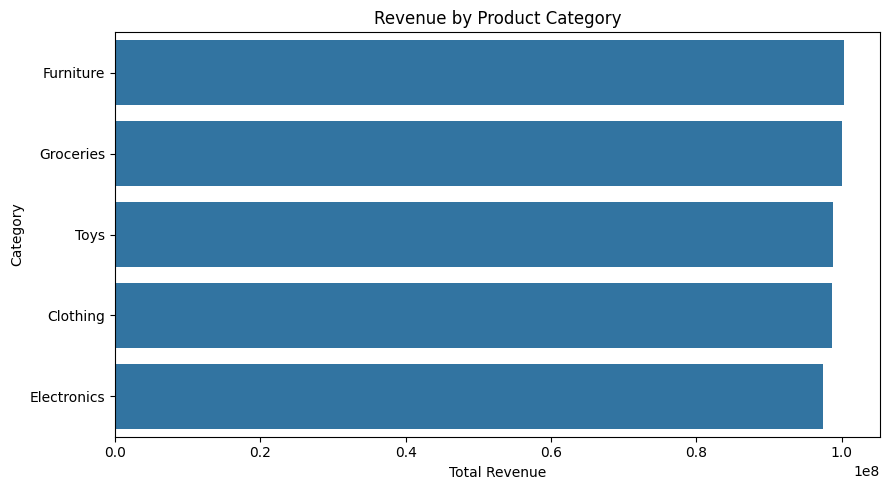

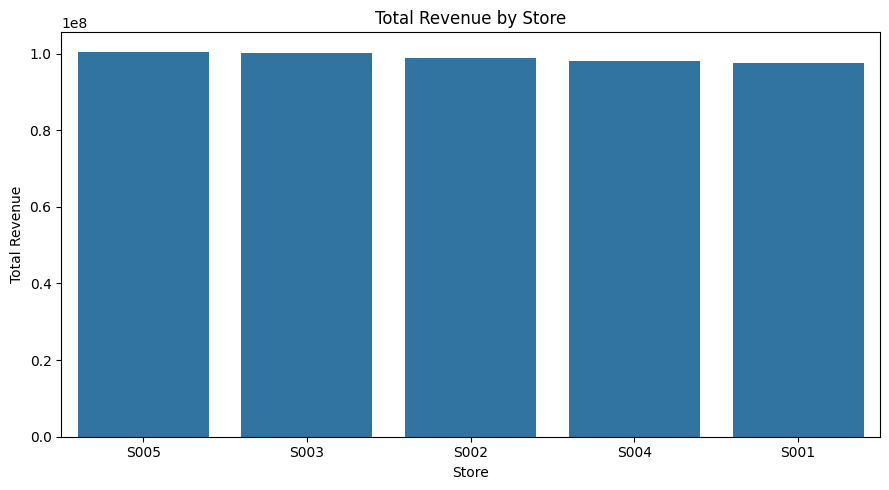

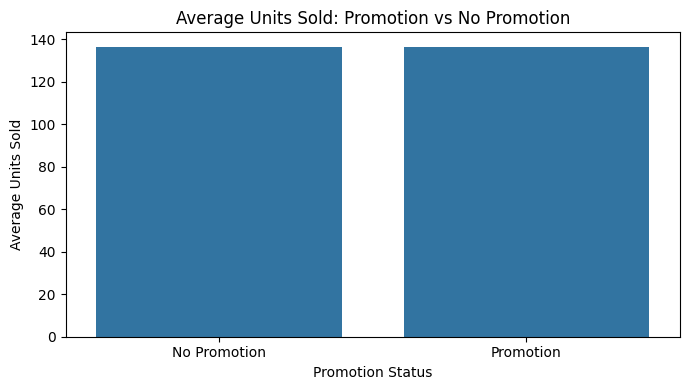

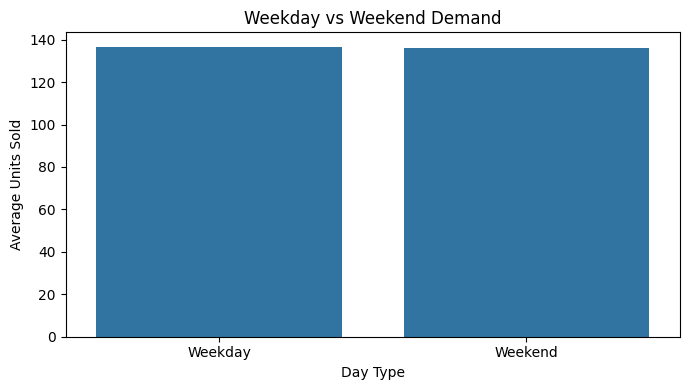

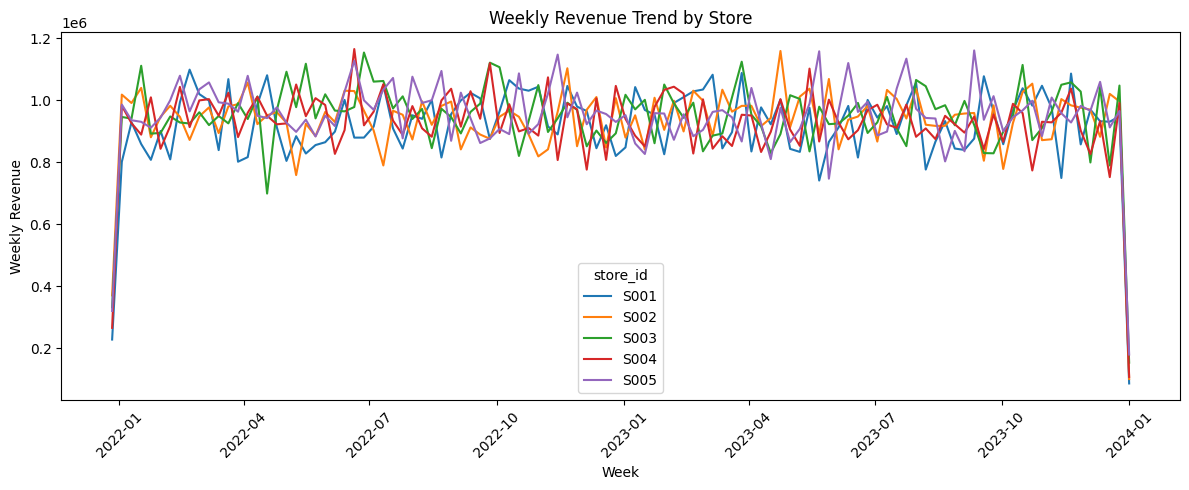

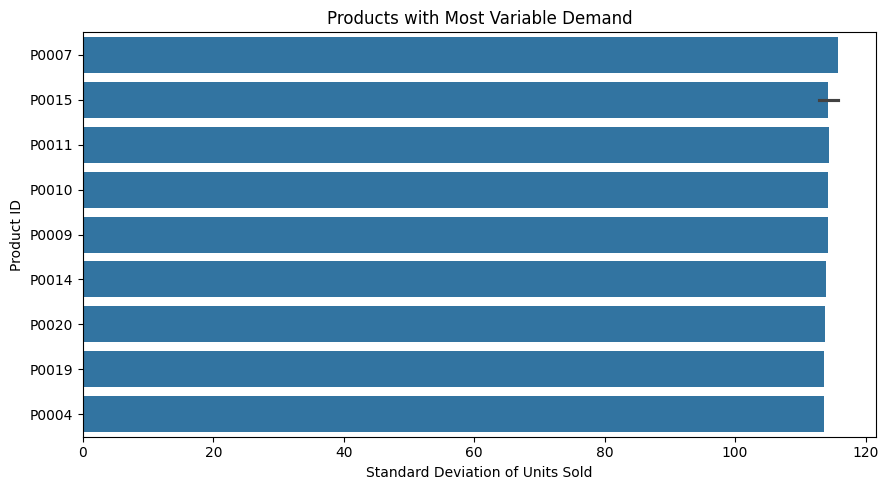

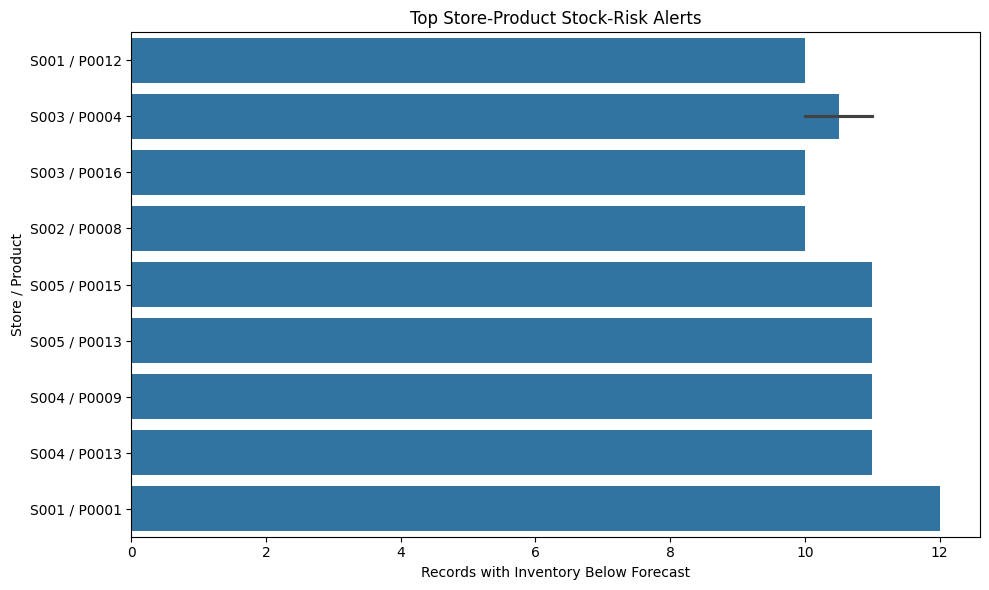

EDA FINDINGS — USE ACTUAL VALUES FROM THIS OUTPUT

1. Highest-revenue category: Furniture, revenue = 100230824.04, share of recorded revenue = 20.25%.

2. Promotion records had average demand 0.06% lower than non-promotion records (promoted=136.42, not promoted=136.51 units).

3. Average units sold: weekday=136.63, weekend=136.06.

4. Records where inventory is below demand forecast: 2683 out of 73100, or 3.67%.

Highest-revenue stores:


,store_id,revenue
4,S005,1.005036e+08
2,S003,1.000344e+08
1,S002,9.895000e+07
3,S004,9.805714e+07
0,S001,9.742619e+07



Top products by demand variability:


,product_id,category,sales_std
33,P0007,Groceries,115.802265
72,P0015,Furniture,115.791498
50,P0011,Clothing,114.372245
47,P0010,Furniture,114.294765
43,P0009,Groceries,114.180102
69,P0014,Toys,113.916415
97,P0020,Furniture,113.853557
92,P0019,Furniture,113.594796
17,P0004,Furniture,113.551916
71,P0015,Electronics,112.830322



Highest-priority store-product combinations:


,store_id,product_id,category,observed_days,risk_days,avg_projected_shortfall,avg_inventory,avg_forecast,avg_units_sold,total_revenue,risk_rate_pct,store_product
0,S001,P0001,Clothing,143,12,0.579161,281.153846,150.802177,144.000000,9.434853e+05,8.391608,S001 / P0001
1,S004,P0009,Clothing,148,11,0.590270,281.668919,158.199375,153.195946,1.079254e+06,7.432432,S004 / P0009
2,S003,P0004,Electronics,154,11,0.494481,281.285714,140.649156,133.519481,1.001366e+06,7.142857,S003 / P0004
3,S005,P0013,Clothing,123,11,0.426585,273.674797,144.715539,138.024390,7.896538e+05,8.943089,S005 / P0013
4,S004,P0013,Groceries,161,11,0.400248,257.105590,132.805652,126.248447,9.957921e+05,6.832298,S004 / P0013
5,S005,P0015,Furniture,144,11,0.385486,294.888889,172.226771,164.618056,1.167467e+06,7.638889,S005 / P0015
6,S001,P0012,Groceries,139,10,1.627410,257.647482,125.707635,118.043165,8.271037e+05,7.194245,S001 / P0012
7,S003,P0004,Clothing,140,10,0.860286,270.985714,127.259438,119.421429,8.236180e+05,7.142857,S003 / P0004
8,S002,P0008,Groceries,144,10,0.849583,246.625000,131.169097,122.437500,8.775897e+05,6.944444,S002 / P0008
9,S003,P0016,Electronics,143,10,0.759091,275.923077,146.399738,141.251748,9.441613e+05,6.993007,S003 / P0016


In [ ]:
# 1. Feature engineering
# Assume Discount is expressed as a percentage, as in your sample.

df["revenue"] = (
    df["units_sold"]
    * df["price"]
    * (1 - df["discount"] / 100)
)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

df["day_type"] = df["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

df["promotion_label"] = np.where(
    df["holiday_promotion"] > 0,
    "Promotion",
    "No Promotion"
)

# A stock-risk proxy: available inventory is below forecast demand.
df["projected_shortfall"] = (
    df["demand_forecast"] - df["inventory_level"]
).clip(lower=0)

df["stock_risk"] = (
    df["inventory_level"] < df["demand_forecast"]
)

# A preliminary excess-stock alert:
# inventory more than twice the positive demand forecast.
df["potential_overstock"] = (
    (df["demand_forecast"] > 0)
    & (df["inventory_level"] > 2 * df["demand_forecast"])
)

# 2. Revenue by category
category_revenue_df = (
    df.groupby("category", as_index=False)["revenue"]
    .sum()
    .sort_values("revenue", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_revenue_df.head(10),
    x="revenue", y="category"
)
plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# 3. Sales/revenue by store
store_revenue_df = (
    df.groupby("store_id", as_index=False)["revenue"]
    .sum()
    .sort_values("revenue", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(data=store_revenue_df, x="store_id", y="revenue")
plt.title("Total Revenue by Store")
plt.xlabel("Store")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

# 4. Compare average units sold with and without promotion
promotion_summary = (
    df.groupby("promotion_label", as_index=False)
    .agg(
        avg_units_sold=("units_sold", "mean"),
        total_records=("units_sold", "size")
    )
)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=promotion_summary,
    x="promotion_label", y="avg_units_sold"
)
plt.title("Average Units Sold: Promotion vs No Promotion")
plt.xlabel("Promotion Status")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

# 5. Weekday vs weekend demand
day_summary = (
    df.groupby("day_type", as_index=False)
    .agg(
        avg_units_sold=("units_sold", "mean"),
        total_records=("units_sold", "size")
    )
)

plt.figure(figsize=(7, 4))
sns.barplot(data=day_summary, x="day_type", y="avg_units_sold")
plt.title("Weekday vs Weekend Demand")
plt.xlabel("Day Type")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

# 6. Weekly sales trend by store
df["week"] = df["date"].dt.to_period("W").dt.start_time

weekly = (
    df.groupby(["week", "store_id"], as_index=False)["revenue"]
    .sum()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=weekly,
    x="week", y="revenue",
    hue="store_id"
)
plt.title("Weekly Revenue Trend by Store")
plt.xlabel("Week")
plt.ylabel("Weekly Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Product demand volatility
product_volatility = (
    df.groupby(["product_id", "category"])["units_sold"]
    .std()
    .dropna()
    .reset_index(name="sales_std")
    .sort_values("sales_std", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=product_volatility.head(10),
    x="sales_std", y="product_id"
)
plt.title("Products with Most Variable Demand")
plt.xlabel("Standard Deviation of Units Sold")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

# 8. Store-product stock-risk summary
attention = (
    df.groupby(["store_id", "product_id", "category"], as_index=False)
    .agg(
        observed_days=("date", "count"),
        risk_days=("stock_risk", "sum"),
        risk_rate=("stock_risk", "mean"),
        avg_projected_shortfall=("projected_shortfall", "mean"),
        avg_inventory=("inventory_level", "mean"),
        avg_forecast=("demand_forecast", "mean"),
        avg_units_sold=("units_sold", "mean"),
        total_revenue=("revenue", "sum")
    )
)

attention["risk_rate_pct"] = attention.pop("risk_rate") * 100

attention["store_product"] = (
    attention["store_id"] + " / " + attention["product_id"]
)

attention = attention.sort_values(
    ["risk_days", "avg_projected_shortfall"],
    ascending=False
).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=attention.head(10).sort_values("risk_days"),
    x="risk_days", y="store_product"
)
plt.title("Top Store-Product Stock-Risk Alerts")
plt.xlabel("Records with Inventory Below Forecast")
plt.ylabel("Store / Product")
plt.tight_layout()
plt.show()

# 9. Print findings based on ACTUAL dataset values
print("EDA FINDINGS — USE ACTUAL VALUES FROM THIS OUTPUT")

if not category_revenue_df.empty:
    top_category = category_revenue_df.iloc[0]
    total_revenue = category_revenue_df["revenue"].sum()

    share = (
        top_category["revenue"] / total_revenue * 100
        if total_revenue > 0 else 0
    )

    print(
        f"\n1. Highest-revenue category: {top_category['category']}, "
        f"revenue = {top_category['revenue']:.2f}, "
        f"share of recorded revenue = {share:.2f}%."
    )

promotion_means = dict(zip(
    promotion_summary["promotion_label"],
    promotion_summary["avg_units_sold"]
))

if "Promotion" in promotion_means and "No Promotion" in promotion_means:
    promoted = promotion_means["Promotion"]
    not_promoted = promotion_means["No Promotion"]

    if not_promoted != 0:
        change_pct = (promoted - not_promoted) / not_promoted * 100
        comparison = "higher" if change_pct > 0 else "lower"

        print(
            f"\n2. Promotion records had average demand "
            f"{abs(change_pct):.2f}% {comparison} than non-promotion "
            f"records (promoted={promoted:.2f}, "
            f"not promoted={not_promoted:.2f} units)."
        )
    else:
        print(
            f"\n2. Mean demand with promotion={promoted:.2f}; "
            f"without promotion={not_promoted:.2f} units."
        )

weekend_means = dict(zip(
    day_summary["day_type"],
    day_summary["avg_units_sold"]
))

if "Weekday" in weekend_means and "Weekend" in weekend_means:
    print(
        f"\n3. Average units sold: weekday={weekend_means['Weekday']:.2f}, "
        f"weekend={weekend_means['Weekend']:.2f}."
    )

risk_pct = df["stock_risk"].mean() * 100

print(
    f"\n4. Records where inventory is below demand forecast: "
    f"{int(df['stock_risk'].sum())} out of {len(df)}, "
    f"or {risk_pct:.2f}%."
)

print("\nHighest-revenue stores:")
display(store_revenue_df.head(5))

print("\nTop products by demand variability:")
display(product_volatility.head(10))

print("\nHighest-priority store-product combinations:")
display(attention.head(10))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target variable
target = "units_sold"

# Selected categorical input features
categorical_features = [
    "store_id", "product_id", "category",
    "region", "weather_condition", "seasonality"
]

# Selected numerical input features
numeric_features = [
    "inventory_level", "units_ordered", "demand_forecast",
    "price", "discount", "holiday_promotion",
    "competitor_pricing", "year", "month",
    "day_of_week", "is_weekend"
]

# Select only the intended ML features.
# Do NOT include revenue, because it is calculated using units_sold.
X = df[categorical_features + numeric_features].copy()
y = df[target].copy()

for col in categorical_features:
    X[col] = X[col].astype(str)

# Prefer a chronological split to test on later dates.
unique_dates = np.sort(df["date"].dropna().unique())

if len(unique_dates) >= 5:
    split_index = int(len(unique_dates) * 0.8)
    split_index = max(1, min(split_index, len(unique_dates) - 1))
    cutoff_date = pd.Timestamp(unique_dates[split_index])

    train_mask = df["date"] < cutoff_date
    test_mask = df["date"] >= cutoff_date

    X_train = X.loc[train_mask].copy()
    X_test = X.loc[test_mask].copy()
    y_train = y.loc[train_mask].copy()
    y_test = y.loc[test_mask].copy()

    print("Evaluation method: chronological train/test split")
    print("Test period begins:", cutoff_date.date())

else:
    # Fallback only when there are too few distinct dates.
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    print("Evaluation method: random 80/20 split")

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Preprocess numerical and categorical columns separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train
model.fit(X_train, y_train)

# Predict on unseen test records
y_pred = model.predict(X_test)

# Actual test-set performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE — ACTUAL TEST RESULTS")
print("Algorithm: Random Forest Regressor")
print("Target: Units Sold")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

# Compare actual vs predicted units sold
prediction_results = pd.DataFrame({
    "Actual_Units_Sold": y_test.to_numpy(),
    "Predicted_Units_Sold": y_pred
})

print("\nActual vs predicted sample:")
display(prediction_results.head(10))

# Identify the most influential model features
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_importance = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": model.named_steps[
            "regressor"
        ].feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 10 MODEL FEATURES")
display(feature_importance.head(10))

Evaluation method: chronological train/test split
Test period begins: 2023-08-08
Training records: 58400
Testing records: 14700

MODEL PERFORMANCE — ACTUAL TEST RESULTS
Algorithm: Random Forest Regressor
Target: Units Sold
MAE  : 7.3752
RMSE : 8.6978
R²   : 0.9935

Actual vs predicted sample:


,Actual_Units_Sold,Predicted_Units_Sold
0,335.0,317.705114
1,239.0,223.061587
2,179.0,172.358193
3,27.0,17.261940
4,23.0,23.621659
5,108.0,103.899111
6,47.0,48.784063
7,259.0,254.270270
8,76.0,64.867148
9,420.0,424.413423



TOP 10 MODEL FEATURES


,feature,importance
0,num__demand_forecast,0.994778
1,num__inventory_level,0.001009
2,num__units_ordered,0.000603
3,num__competitor_pricing,0.000459
4,num__price,0.000456
5,num__month,0.000342
6,num__day_of_week,0.000244
7,num__discount,0.000214
8,num__holiday_promotion,0.000083
9,num__year,0.000071


PROTOTYPE: STOCK-RISK ALERT TABLE
Risk rule: Inventory Level < Demand Forecast


,store_id,product_id,category,observed_days,risk_days,avg_projected_shortfall,avg_inventory,avg_forecast,avg_units_sold,total_revenue,risk_rate_pct,store_product
0,S001,P0001,Clothing,143,12,0.579161,281.153846,150.802177,144.000000,9.434853e+05,8.391608,S001 / P0001
1,S004,P0009,Clothing,148,11,0.590270,281.668919,158.199375,153.195946,1.079254e+06,7.432432,S004 / P0009
2,S003,P0004,Electronics,154,11,0.494481,281.285714,140.649156,133.519481,1.001366e+06,7.142857,S003 / P0004
3,S005,P0013,Clothing,123,11,0.426585,273.674797,144.715539,138.024390,7.896538e+05,8.943089,S005 / P0013
4,S004,P0013,Groceries,161,11,0.400248,257.105590,132.805652,126.248447,9.957921e+05,6.832298,S004 / P0013
5,S005,P0015,Furniture,144,11,0.385486,294.888889,172.226771,164.618056,1.167467e+06,7.638889,S005 / P0015
6,S001,P0012,Groceries,139,10,1.627410,257.647482,125.707635,118.043165,8.271037e+05,7.194245,S001 / P0012
7,S003,P0004,Clothing,140,10,0.860286,270.985714,127.259438,119.421429,8.236180e+05,7.142857,S003 / P0004
8,S002,P0008,Groceries,144,10,0.849583,246.625000,131.169097,122.437500,8.775897e+05,6.944444,S002 / P0008
9,S003,P0016,Electronics,143,10,0.759091,275.923077,146.399738,141.251748,9.441613e+05,6.993007,S003 / P0016



POTENTIAL EXCESS-STOCK ALERTS


,store_id,product_id,category,overstock_records,avg_inventory,avg_forecast,total_revenue
440,S005,P0009,Clothing,96,259.718750,71.134167,314976.6070
437,S005,P0008,Furniture,92,286.173913,72.873370,329839.6945
407,S005,P0002,Furniture,92,291.739130,76.303152,300076.6715
175,S002,P0016,Clothing,92,280.500000,70.029239,331522.3420
446,S005,P0010,Electronics,91,284.197802,79.928791,354726.1080
54,S001,P0011,Toys,90,286.544444,72.316444,281266.7795
483,S005,P0017,Groceries,89,303.528090,69.126966,287735.6470
241,S003,P0009,Electronics,88,268.238636,73.469659,303481.7545
232,S003,P0007,Furniture,87,282.758621,76.917586,340606.9005
382,S004,P0017,Furniture,87,262.678161,77.667471,328293.0790


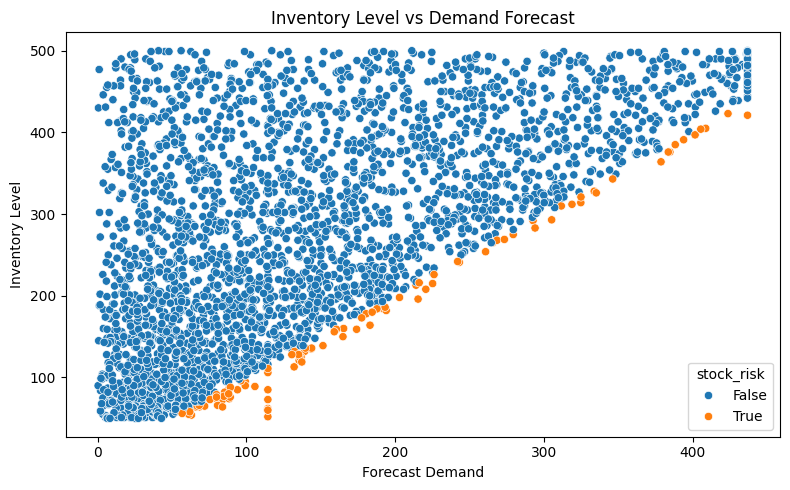


PRACTICAL RECOMMENDATIONS
1. Review replenishment for Store S001, Product P0001. It has 12 records where inventory is below forecast demand.
2. Review ordering and stock allocation for Store S005, Product P0009, which meets the preliminary excess-stock rule.
3. Review promotion performance by product and category before allocating additional promotional inventory.

Prototype description: The system uses a demand prediction model and rule-based inventory alerts to flag store-product combinations that may need replenishment or excess-stock review.

FILES CREATED SUCCESSFULLY
1. cleaned_retail_inventory.csv
2. DS_Sprint_Retail_Stock_Insight.xlsx


In [ ]:
# 1. Show the highest-priority stock-risk alerts
priority_alerts = attention.loc[
    attention["risk_days"] > 0
].head(10)

print("PROTOTYPE: STOCK-RISK ALERT TABLE")
print("Risk rule: Inventory Level < Demand Forecast")
display(priority_alerts)

# 2. Show potential excess-stock alerts
# This uses an illustrative threshold of inventory > 2 x forecast.
overstock_alerts = (
    df.loc[df["potential_overstock"]]
    .groupby(
        ["store_id", "product_id", "category"],
        as_index=False
    )
    .agg(
        overstock_records=("date", "count"),
        avg_inventory=("inventory_level", "mean"),
        avg_forecast=("demand_forecast", "mean"),
        total_revenue=("revenue", "sum")
    )
    .sort_values("overstock_records", ascending=False)
)

print("\nPOTENTIAL EXCESS-STOCK ALERTS")
display(overstock_alerts.head(10))

# 3. Inventory versus demand forecast visualization
plot_data = df.sample(min(3000, len(df)), random_state=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_data,
    x="demand_forecast",
    y="inventory_level",
    hue="stock_risk"
)
plt.title("Inventory Level vs Demand Forecast")
plt.xlabel("Forecast Demand")
plt.ylabel("Inventory Level")
plt.tight_layout()
plt.show()

# 4. Generate data-driven recommendations
print("\nPRACTICAL RECOMMENDATIONS")

if not priority_alerts.empty:
    row = priority_alerts.iloc[0]

    print(
        f"1. Review replenishment for Store {row['store_id']}, "
        f"Product {row['product_id']}. "
        f"It has {int(row['risk_days'])} records where inventory "
        f"is below forecast demand."
    )
else:
    print(
        "1. No records meet the inventory-below-forecast rule. "
        "Continue monitoring inventory against future demand."
    )

if not overstock_alerts.empty:
    row = overstock_alerts.iloc[0]

    print(
        f"2. Review ordering and stock allocation for Store "
        f"{row['store_id']}, Product {row['product_id']}, "
        "which meets the preliminary excess-stock rule."
    )
else:
    print(
        "2. No records meet the preliminary excess-stock rule. "
        "Continue tracking inventory coverage and demand."
    )

if (
    "Promotion" in promotion_means
    and "No Promotion" in promotion_means
):
    if promotion_means["Promotion"] > promotion_means["No Promotion"]:
        print(
            "3. Investigate whether promotions are associated with "
            "higher demand, while checking margins and stock availability."
        )
    else:
        print(
            "3. Review promotion performance by product and category "
            "before allocating additional promotional inventory."
        )

print(
    "\nPrototype description: The system uses a demand prediction model "
    "and rule-based inventory alerts to flag store-product combinations "
    "that may need replenishment or excess-stock review."
)

# 5. Prepare the model metrics sheet
model_metrics = pd.DataFrame([{
    "Algorithm": "Random Forest Regressor",
    "Target": "Units Sold",
    "Train_Records": len(X_train),
    "Test_Records": len(X_test),
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}])

# 6. Export the cleaned data and assessment workbook
df.to_csv("cleaned_retail_inventory.csv", index=False)

with pd.ExcelWriter(
    "DS_Sprint_Retail_Stock_Insight.xlsx",
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )

    category_revenue_df.to_excel(
        writer, sheet_name="Category_Revenue", index=False
    )

    store_revenue_df.to_excel(
        writer, sheet_name="Store_Revenue", index=False
    )

    promotion_summary.to_excel(
        writer, sheet_name="Promotion_Analysis", index=False
    )

    day_summary.to_excel(
        writer, sheet_name="Day_Type_Analysis", index=False
    )

    weekly.to_excel(
        writer, sheet_name="Weekly_Store_Sales", index=False
    )

    attention.to_excel(
        writer, sheet_name="Stock_Risk_Alerts", index=False
    )

    product_volatility.to_excel(
        writer, sheet_name="Demand_Volatility", index=False
    )

    model_metrics.to_excel(
        writer, sheet_name="Model_Performance", index=False
    )

    feature_importance.head(30).to_excel(
        writer, sheet_name="Feature_Importance", index=False
    )

print("\nFILES CREATED SUCCESSFULLY")
print("1. cleaned_retail_inventory.csv")
print("2. DS_Sprint_Retail_Stock_Insight.xlsx")

In [ ]:
from google.colab import files
files.download("DS_Sprint_Retail_Stock_Insight.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=== DATASET & PREPROCESSING ===")
print("Original records:", original_shape[0])
print("Original attributes:", original_shape[1])
print("Initial missing cells:", int(original_missing_counts.sum()))
print("Invalid date rows removed:", invalid_date_rows)
print("Duplicate rows removed:", duplicates_removed)
print("Missing/invalid target rows removed:", missing_target_rows)
print("Outlier values capped:", sum(outlier_counts.values()))
print("Final cleaned records:", len(df))
print("Remaining missing cells:", int(df.isna().sum().sum()))

print("\n=== CATEGORY REVENUE (DESCENDING) ===")
display(
    category_revenue_df
    .sort_values("revenue", ascending=False)
    .round(2)
)

print("\n=== PROMOTION COMPARISON ===")
display(promotion_summary.round(2))

print("\n=== WEEKDAY VS WEEKEND ===")
display(day_summary.round(2))

print("\n=== STOCK RISK ===")
print("Records below forecast:", int(df["stock_risk"].sum()))
print(
    "Percentage:",
    round(df["stock_risk"].mean() * 100, 2), "%"
)

print("\n=== MODEL PERFORMANCE ===")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 5))

=== DATASET & PREPROCESSING ===
Original records: 73100
Original attributes: 15
Initial missing cells: 0
Invalid date rows removed: 0
Duplicate rows removed: 0
Missing/invalid target rows removed: 0
Outlier values capped: 791
Final cleaned records: 73100
Remaining missing cells: 0

=== CATEGORY REVENUE (DESCENDING) ===


,category,revenue
2,Furniture,1.002308e+08
3,Groceries,9.994897e+07
4,Toys,9.872922e+07
0,Clothing,9.867678e+07
1,Electronics,9.738559e+07



=== PROMOTION COMPARISON ===


,promotion_label,avg_units_sold,total_records
0,No Promotion,136.51,36747
1,Promotion,136.42,36353



=== WEEKDAY VS WEEKEND ===


,day_type,avg_units_sold,total_records
0,Weekday,136.63,52100
1,Weekend,136.06,21000



=== STOCK RISK ===
Records below forecast: 2683
Percentage: 3.67 %

=== MODEL PERFORMANCE ===
MAE: 7.3752
RMSE: 8.6978
R²: 0.99354


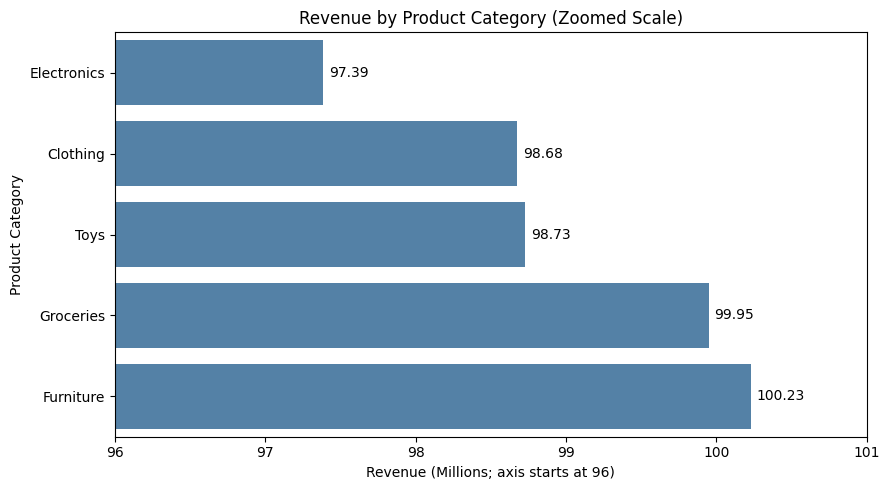

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert revenue into millions
plot_df = category_revenue_df.copy()
plot_df["revenue_million"] = plot_df["revenue"] / 1_000_000

plot_df = plot_df.sort_values("revenue_million")

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot_df,
    x="revenue_million",
    y="category",
    color="steelblue"
)

# Show exact revenue values
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4)

# Zoom the axis to highlight differences
ax.set_xlim(96, 101)

plt.title("Revenue by Product Category (Zoomed Scale)")
plt.xlabel("Revenue (Millions; axis starts at 96)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

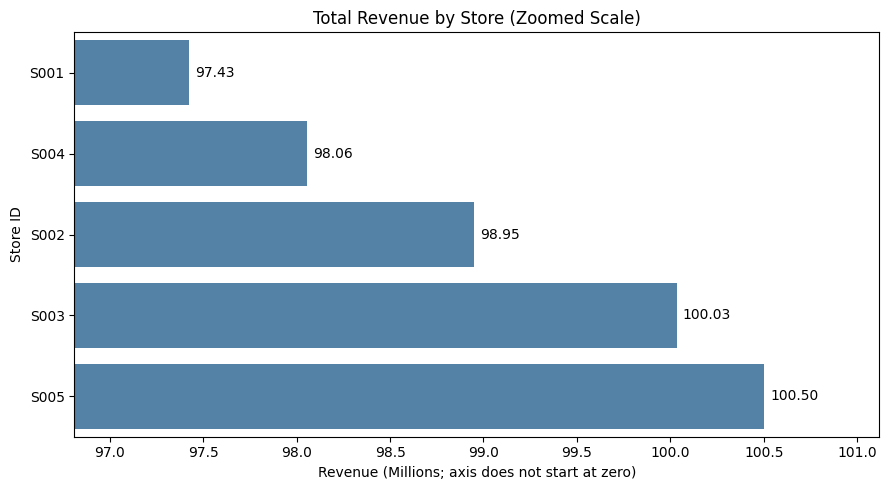

In [ ]:
plot_df = store_revenue_df.copy()
plot_df["revenue_million"] = plot_df["revenue"] / 1_000_000
plot_df = plot_df.sort_values("revenue_million")

values = plot_df["revenue_million"]
pad = max((values.max() - values.min()) * 0.2, 0.1)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot_df,
    x="revenue_million",
    y="store_id",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
ax.set_xlim(max(0, values.min() - pad), values.max() + pad)

plt.title("Total Revenue by Store (Zoomed Scale)")
plt.xlabel("Revenue (Millions; axis does not start at zero)")
plt.ylabel("Store ID")
plt.tight_layout()
plt.show()

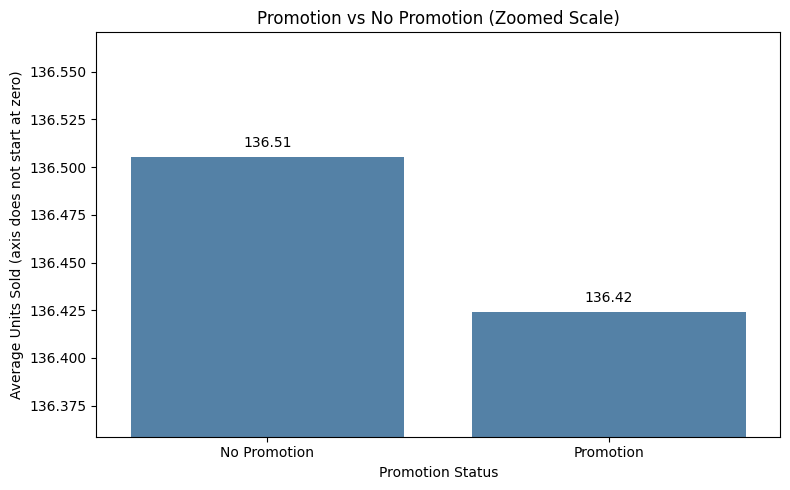

In [ ]:
plot_df = promotion_summary.copy()

values = plot_df["avg_units_sold"]
pad = max((values.max() - values.min()) * 0.8, 0.05)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=plot_df,
    x="promotion_label",
    y="avg_units_sold",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=5)
ax.set_ylim(values.min() - pad, values.max() + pad)

plt.title("Promotion vs No Promotion (Zoomed Scale)")
plt.xlabel("Promotion Status")
plt.ylabel("Average Units Sold (axis does not start at zero)")
plt.tight_layout()
plt.show()

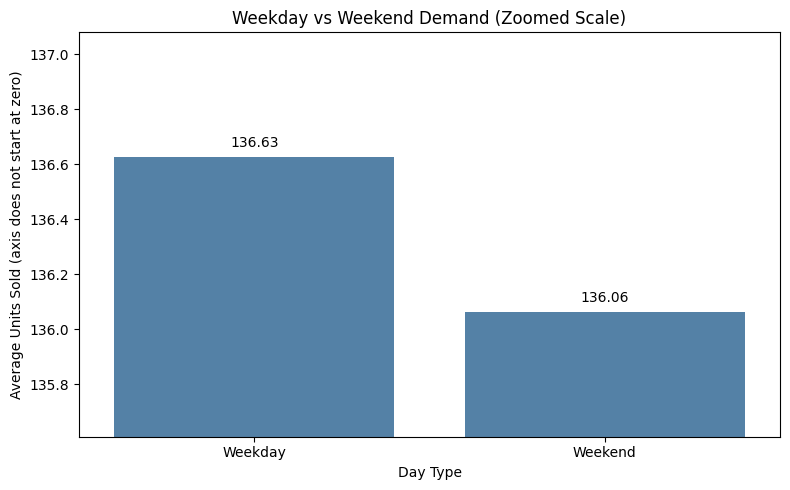

In [ ]:
plot_df = day_summary.copy()

values = plot_df["avg_units_sold"]
pad = max((values.max() - values.min()) * 0.8, 0.05)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=plot_df,
    x="day_type",
    y="avg_units_sold",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=5)
ax.set_ylim(values.min() - pad, values.max() + pad)

plt.title("Weekday vs Weekend Demand (Zoomed Scale)")
plt.xlabel("Day Type")
plt.ylabel("Average Units Sold (axis does not start at zero)")
plt.tight_layout()
plt.show()